# Customer Churn Prediction ML Project

**📝 Problem Statement**

* A telecommunications company wants to predict whether a customer will churn (leave the company) based on the customer's demographic information, services, contract details, and billing information. 
* The goal is to identify customers who are likely to leave so the company can take retention actions.

Template:
- **What is the problem?**	`whether a customer will churn or not`
- **What is the target?**	    `Which column is the answer?`
- **Target type?**	        `Category`
- **ML type?**	            `Classification`
- **What are X?**	            
    'gender', 'senior_citizen', 'partner', 'dependents', 'tenure','phone_service','multiple_lines', 'internet_service',
    'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract''paperless_billing',
    'payment_method', 'monthly_charges', 'total_charges'
- **what are y?**             `churn`
- **Which metric?**	        `accuracy_score, f1_score, recall_score, precision_score`

**Step 1: Import Libraries**

In [43]:
# data handling 
import pandas as pd
import numpy as np
import joblib

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# feature selection
from sklearn.feature_selection import VarianceThreshold

# classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# metrics
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

**Step 2: Load Dataset**

In [2]:
df = pd.read_csv("2_Telco-Customer-Churn.csv")

**Step 3: Understand Your Data (EDA)**

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1475,6048-UWKAL,Female,1,Yes,No,69,Yes,Yes,Fiber optic,No,Yes,No,Yes,Yes,Yes,Two year,No,Credit card (automatic),105.40,6998.95,No
2299,6177-PEVRA,Female,0,No,No,48,Yes,No,DSL,Yes,Yes,No,No,No,No,Two year,No,Credit card (automatic),55.50,2627.35,No
1697,3795-GWTRD,Female,0,Yes,Yes,63,Yes,No,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),75.55,4707.85,No
1439,0506-LVNGN,Female,1,No,No,5,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,Yes,Credit card (automatic),75.55,349.65,Yes
4582,6122-LJADA,Male,0,Yes,Yes,70,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),90.15,6237.05,No


In [5]:
df.shape

(7043, 21)

In [6]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [7]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [8]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


**Step 4: Data Cleaning**

In [12]:
# 1. check missing values
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
# 2. remove dulicates

print(f"duplicate valies: {df.duplicated().sum()}")
df = df.drop_duplicates()

duplicate valies: 0


In [16]:
# 3. remove unwanted cols
df.drop(columns=['customerID'], inplace=True)

In [18]:
# 4. fix col names
df = df.rename(columns={
    "SeniorCitizen": "senior_citizen",
    "Partner": "partner",
    "Dependents": "dependents",
    "PhoneService": "phone_service",
    "MultipleLines": "multiple_lines",
    "InternetService": "internet_service",
    "OnlineSecurity": "online_security",
    "OnlineBackup": "online_backup",
    "DeviceProtection": "device_protection",
    "TechSupport": "tech_support",
    "StreamingTV": "streaming_tv",
    "StreamingMovies": "streaming_movies",
    "Contract": "contract",
    "PaperlessBilling": "paperless_billing",
    "PaymentMethod": "payment_method",
    "MonthlyCharges": "monthly_charges",
    "TotalCharges": "total_charges",
    "Churn": "churn",
    })


In [21]:
# 5. fix datatypes
df['total_charges'] = pd.to_numeric(df['total_charges'], errors='coerce')

<Axes: >

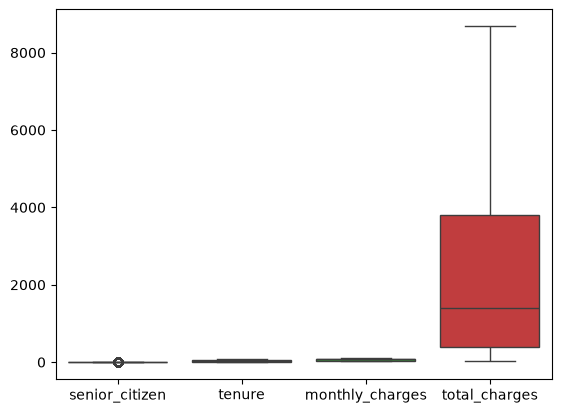

In [25]:
# 6. remove outliers
sns.boxplot(df[df.select_dtypes(include=[int,float]).columns.to_list()])

In [27]:
cols = df.select_dtypes(include=[int,float]).columns.to_list()
for i,col in enumerate(cols, start=1):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    
    lower = q1 - (1.5 * iqr)
    upper = q3 + (1.5 * iqr)
    
    before_outliers = df[(df[col] < lower) | (df[col] > upper)]
    df[col] = df[col].clip(lower,upper)
    after_outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(f"\n{i}. {col}")
    print(f"before outliers: {len(before_outliers)}")
    print(f"after outliers: {len(after_outliers)}")


1. senior_citizen
before outliers: 0
after outliers: 0

2. tenure
before outliers: 0
after outliers: 0

3. monthly_charges
before outliers: 0
after outliers: 0

4. total_charges
before outliers: 0
after outliers: 0


**Step 5: Feature Engineering**

In [29]:
# Calculate the ratio (adding 1 to prevent division by zero errors)
df['charges_ratio'] = (df['monthly_charges'] * df['tenure']) / (df['total_charges'] + 1)

# Bin tenure into 4 distinct groups
df['tenure_group'] = pd.cut(df['tenure'], 
                            bins=[-1, 6, 12, 24, df['tenure'].max()], 
                            labels=['0-6m_New', '6-12m_Struggling', '1-2y_Stable', '2y+_Loyal'])

# Identify paperless/auto-pay tech-savvy users with stable contracts
df['is_locked_in'] = (
    (df['contract'].isin(['One year', 'Two year'])) & 
    (df['payment_method'].str.contains('automatic', case=False))
).astype(int)


**Step 6: Data Visualization**

In [30]:
df.nunique()

gender                  2
senior_citizen          1
partner                 2
dependents              2
tenure                 73
phone_service           2
multiple_lines          3
internet_service        3
online_security         3
online_backup           3
device_protection       3
tech_support            3
streaming_tv            3
streaming_movies        3
contract                3
paperless_billing       2
payment_method          4
monthly_charges      1585
total_charges        6530
churn                   2
charges_ratio        6766
tenure_group            4
is_locked_in            2
dtype: int64

Univariate:

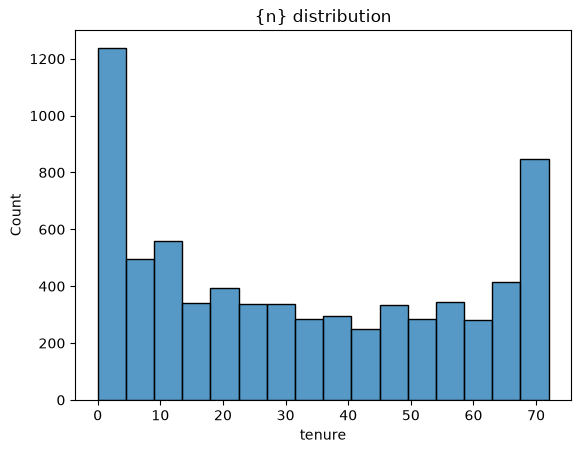

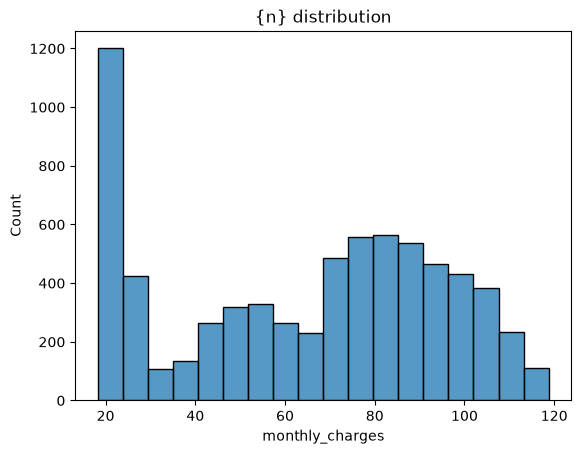

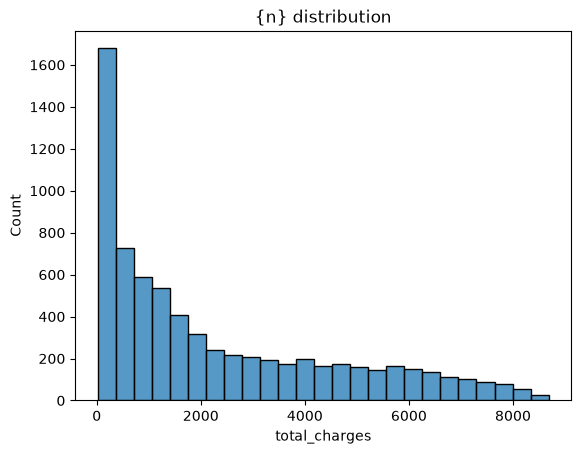

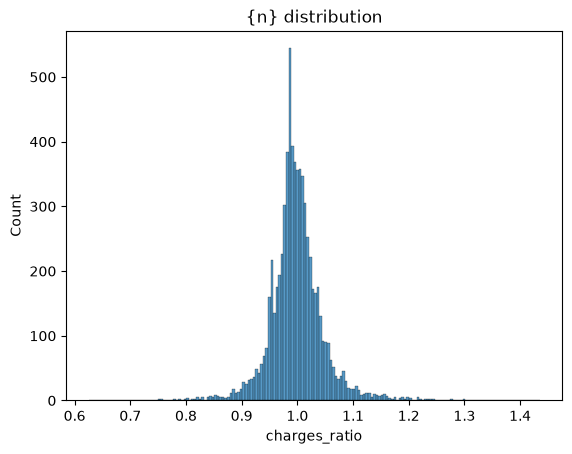

In [32]:
nums = [ 'tenure','monthly_charges', 'total_charges', 'charges_ratio']
for n in nums:
    sns.histplot(data=df,x=n)
    plt.title("{n} distribution")
    plt.show()

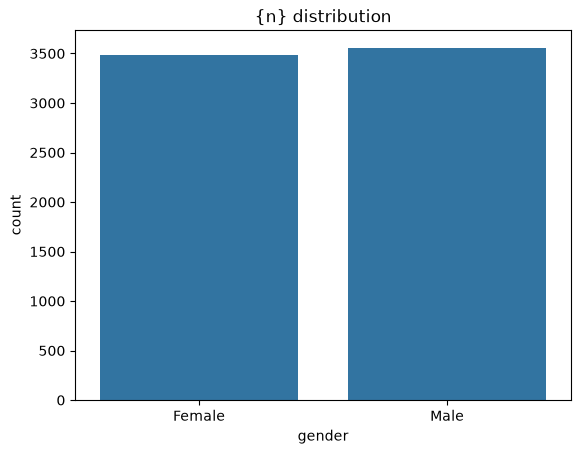

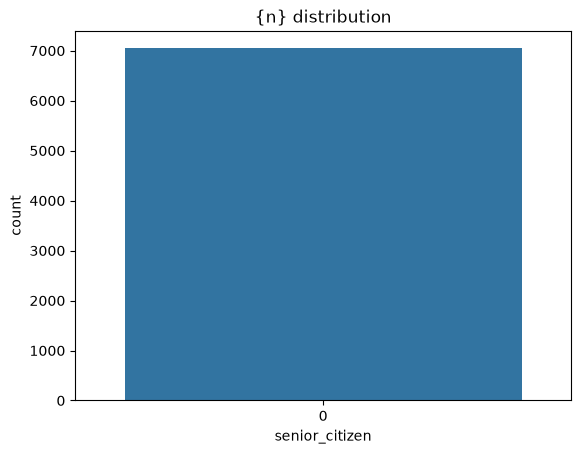

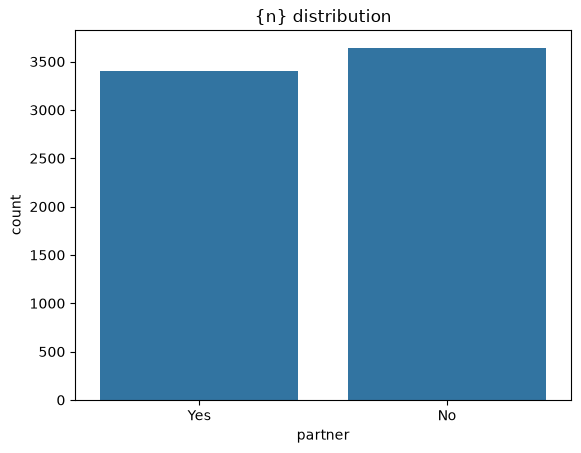

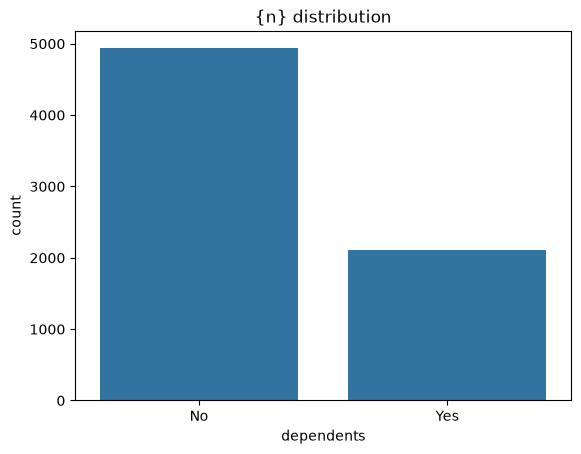

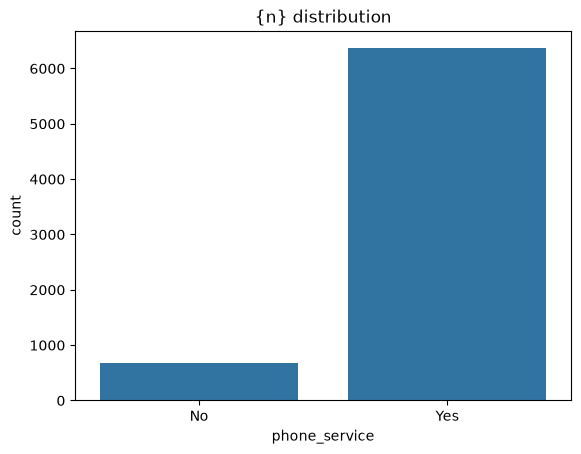

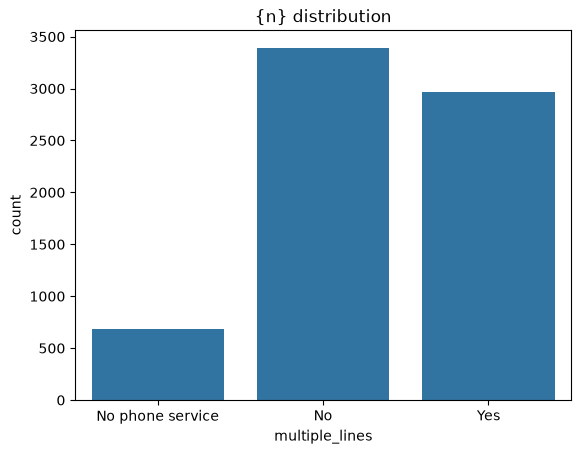

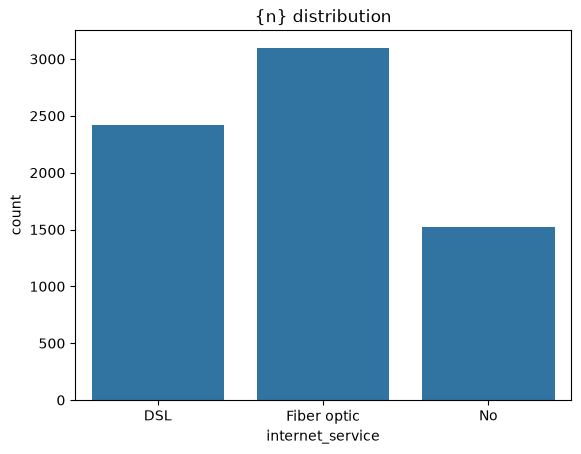

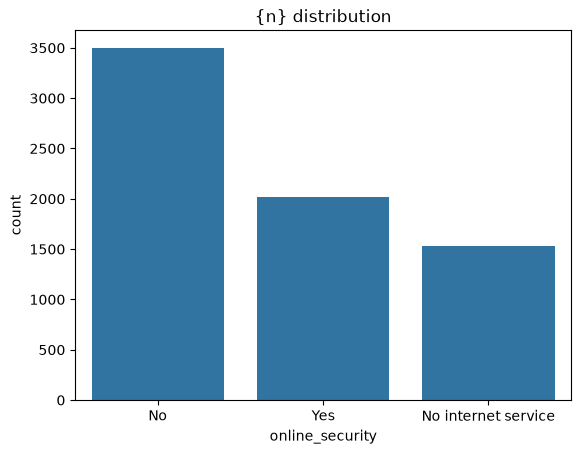

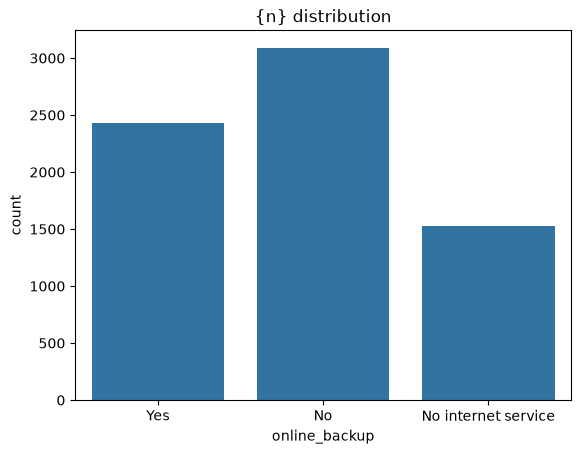

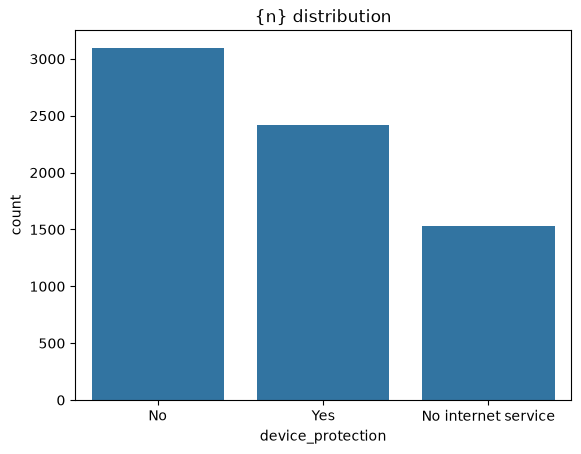

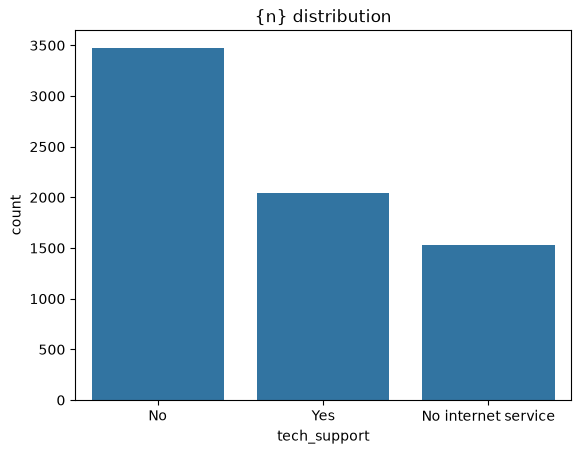

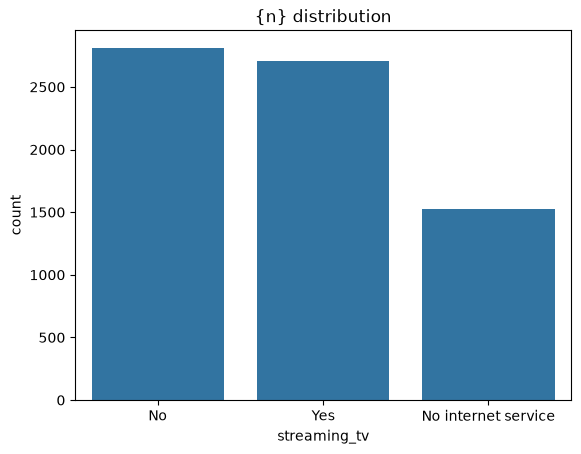

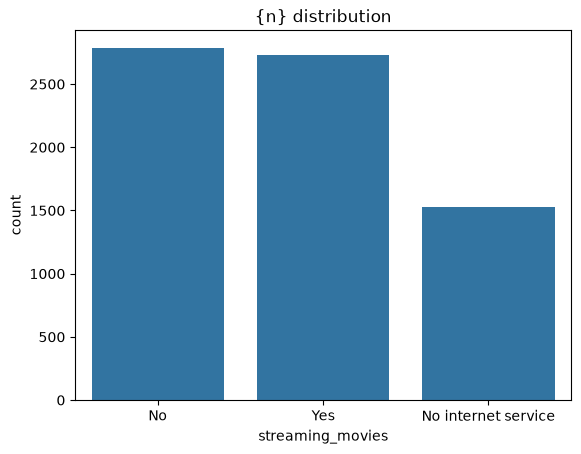

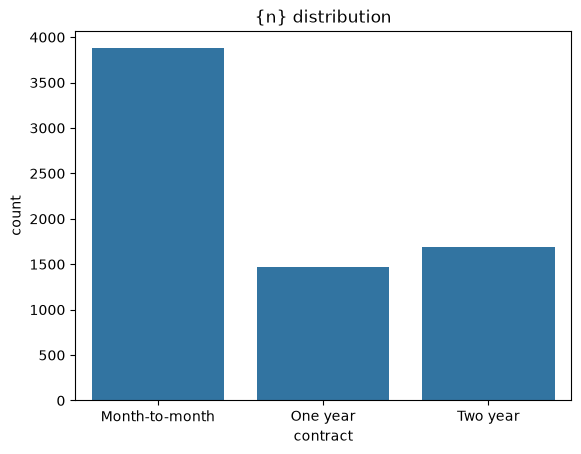

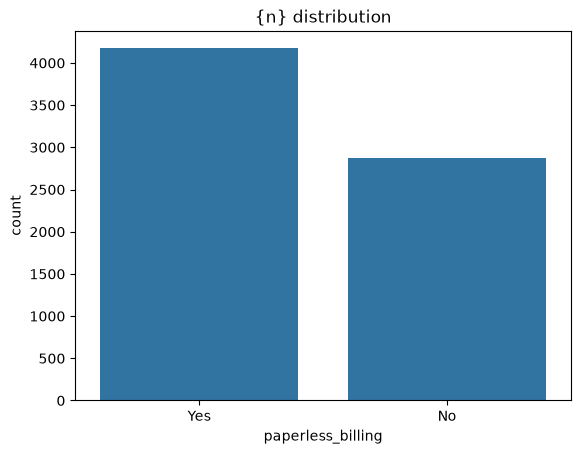

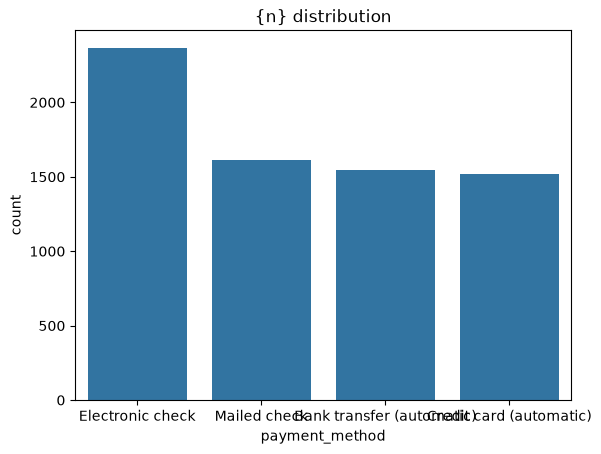

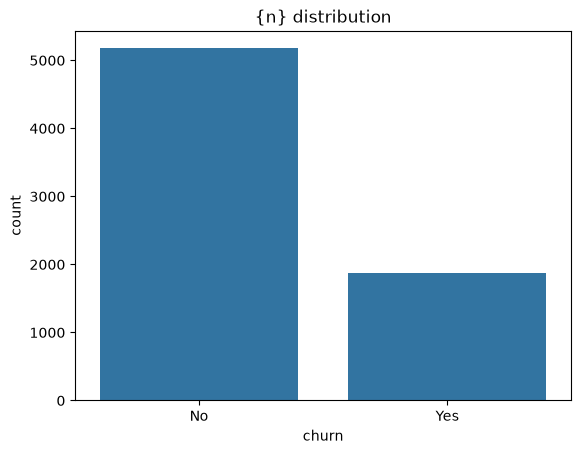

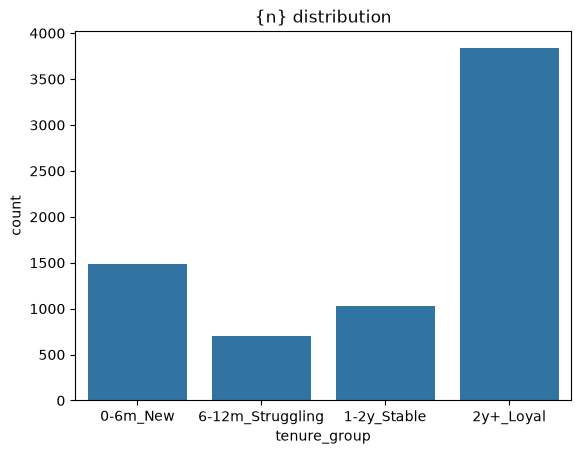

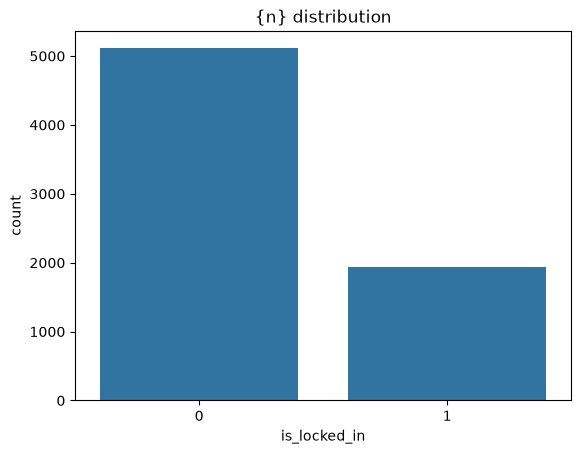

In [33]:
cats = ['gender', 'senior_citizen', 'partner', 'dependents',
       'phone_service', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing',
       'payment_method', 'churn','tenure_group', 'is_locked_in']
for n in cats:
    sns.countplot(data=df,x=n)
    plt.title("{n} distribution")
    plt.show()

Bivariate & Multivariate:

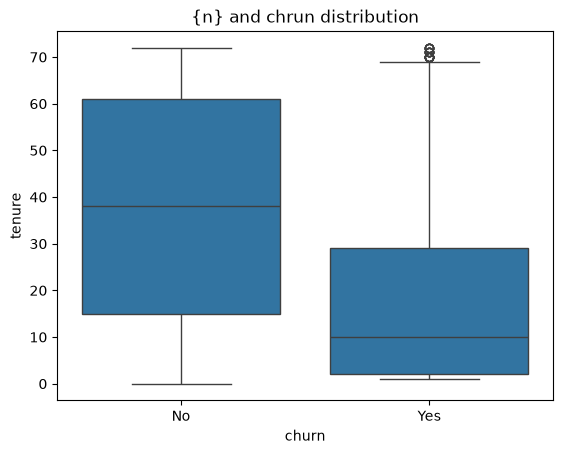

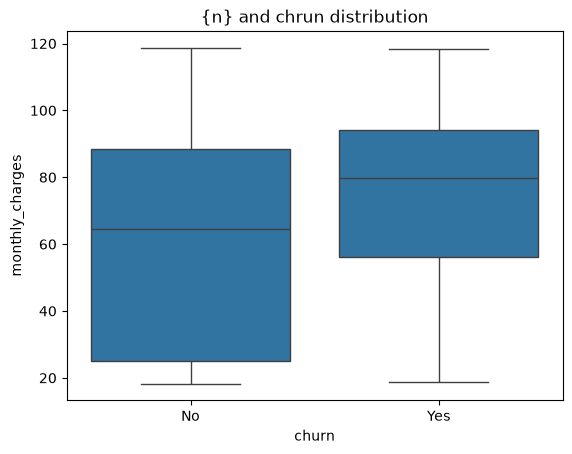

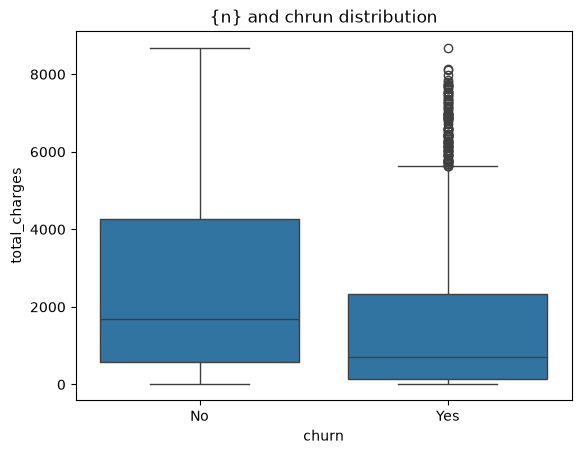

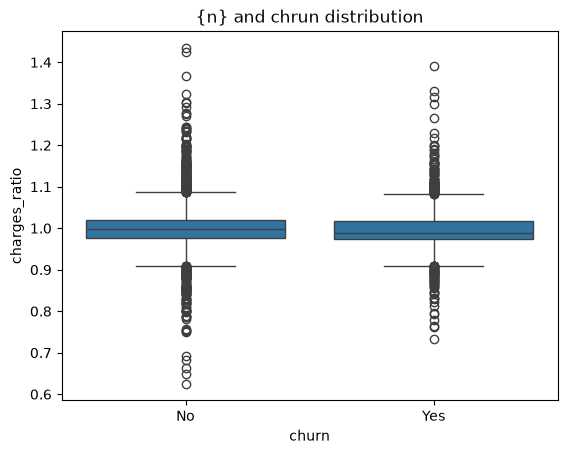

In [34]:
nums = [ 'tenure','monthly_charges', 'total_charges', 'charges_ratio']
for n in nums:
    sns.boxplot(data=df,x='churn', y=n)
    plt.title("{n} and chrun distribution")
    plt.show()

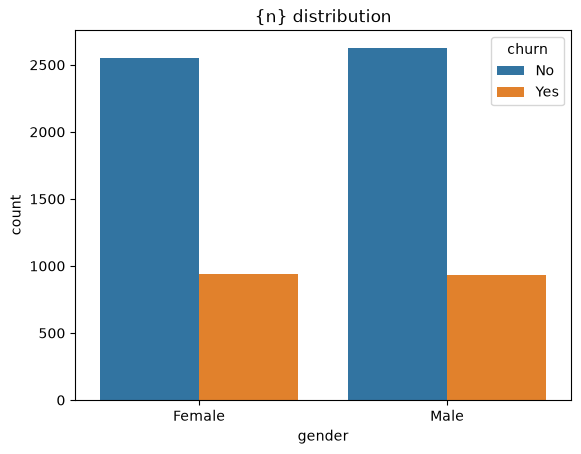

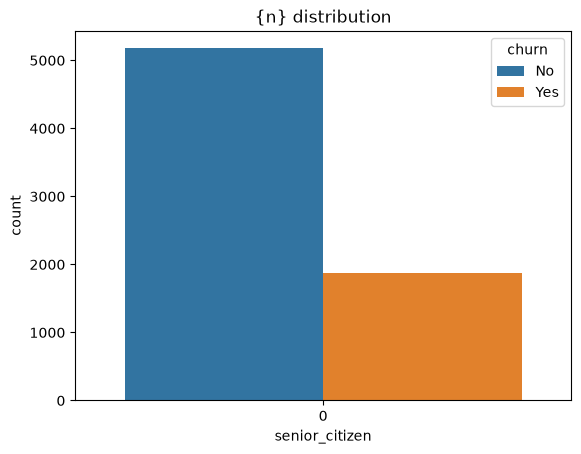

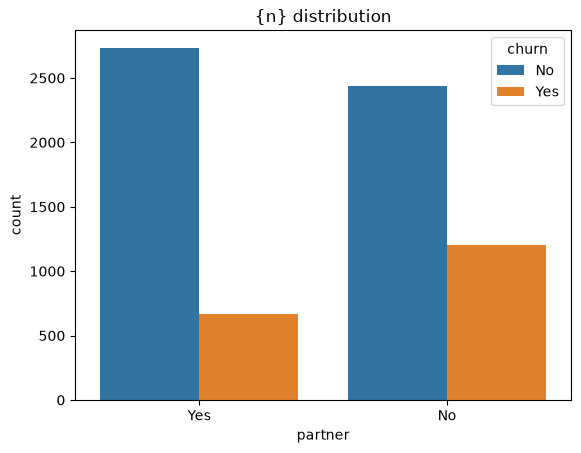

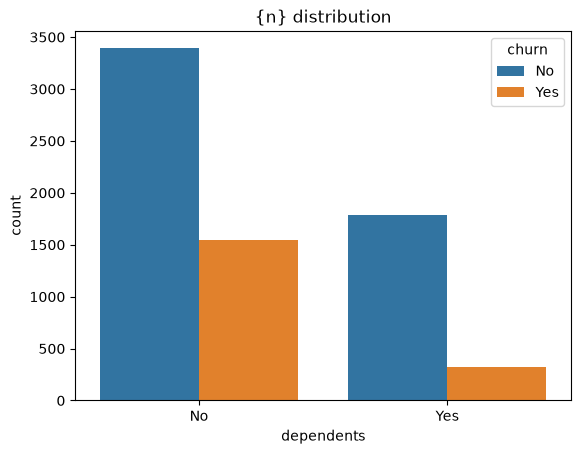

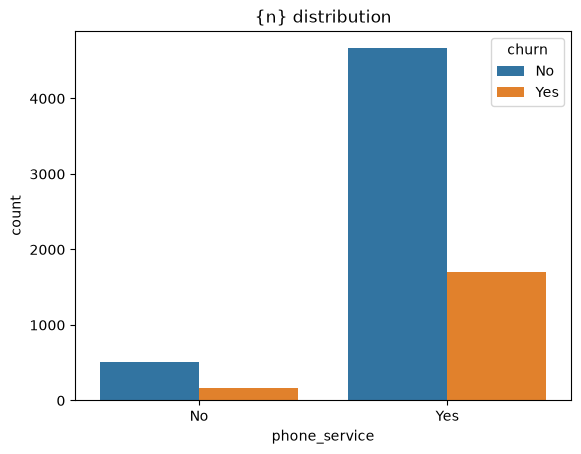

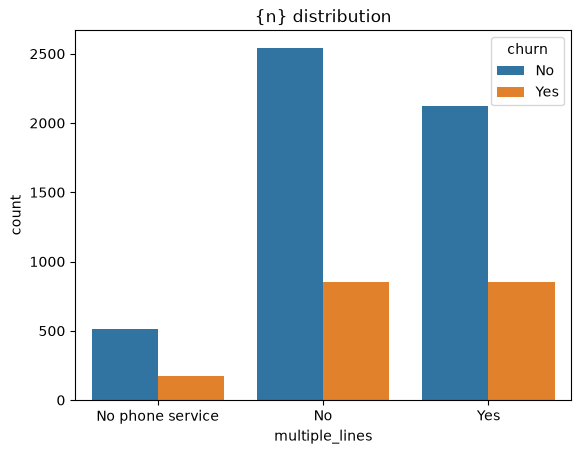

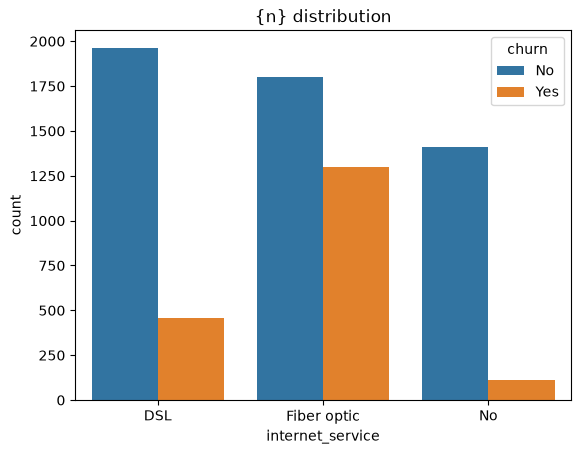

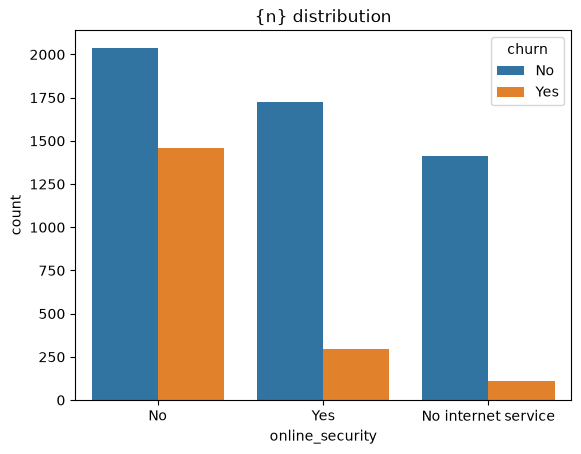

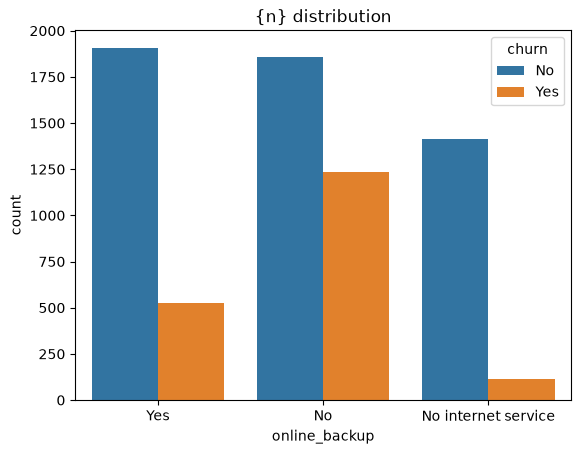

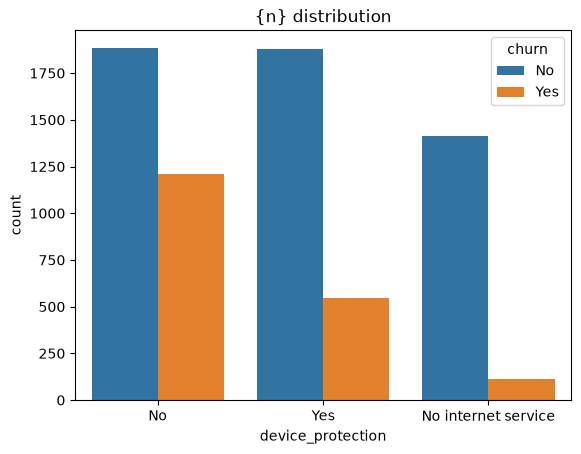

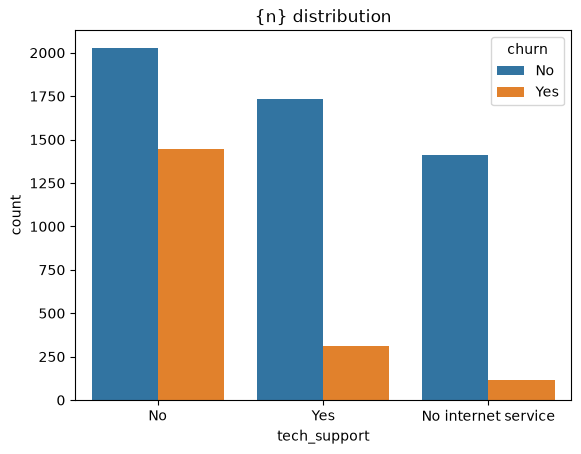

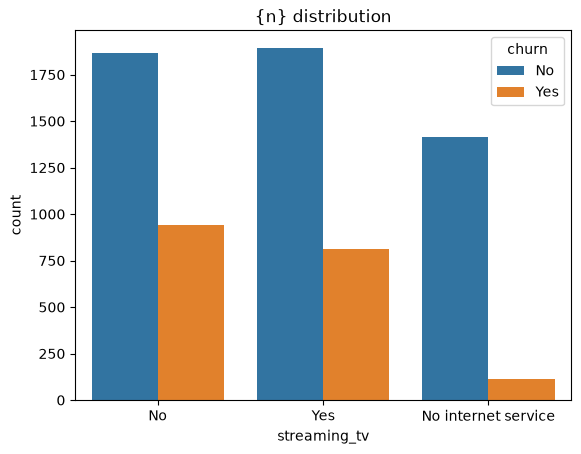

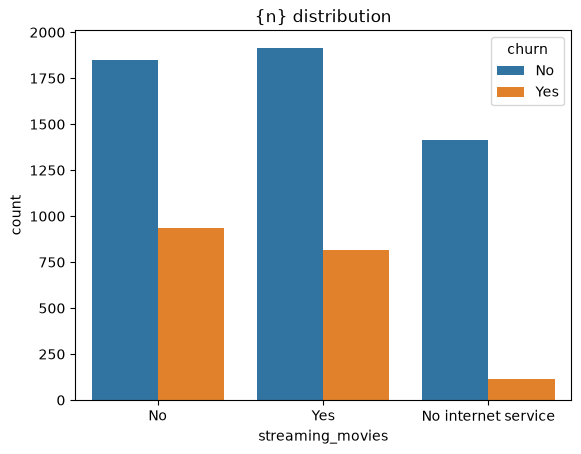

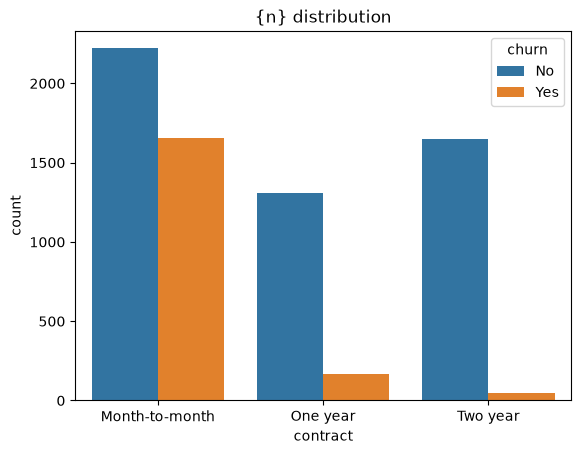

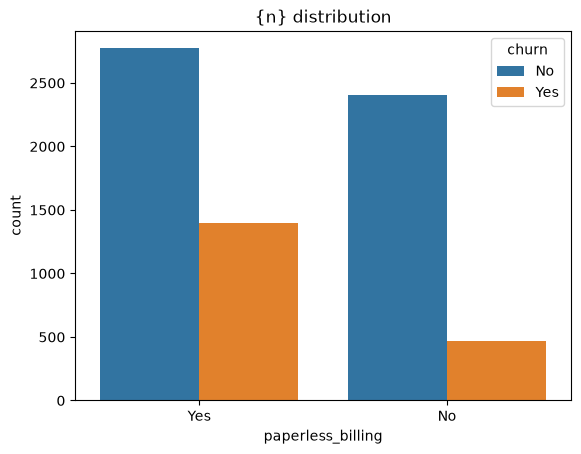

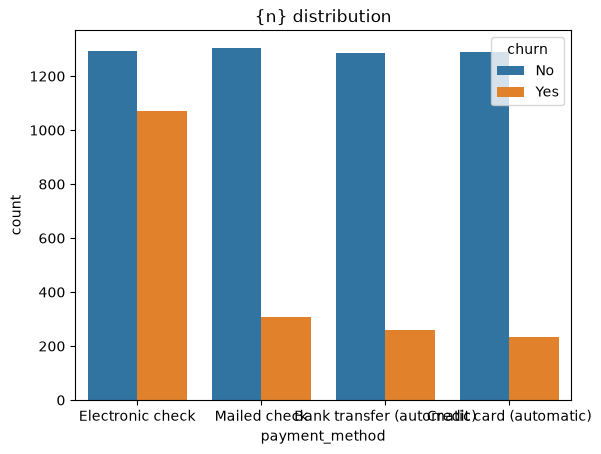

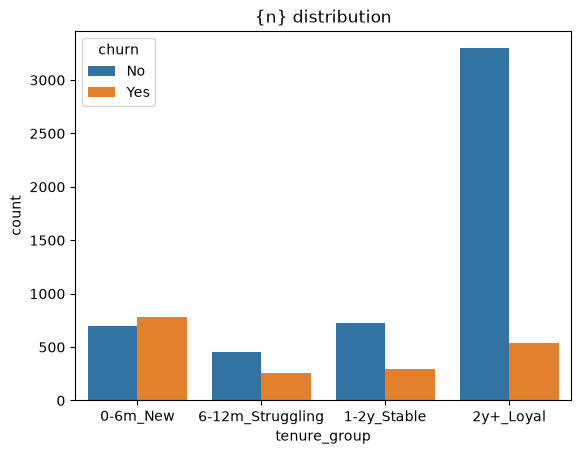

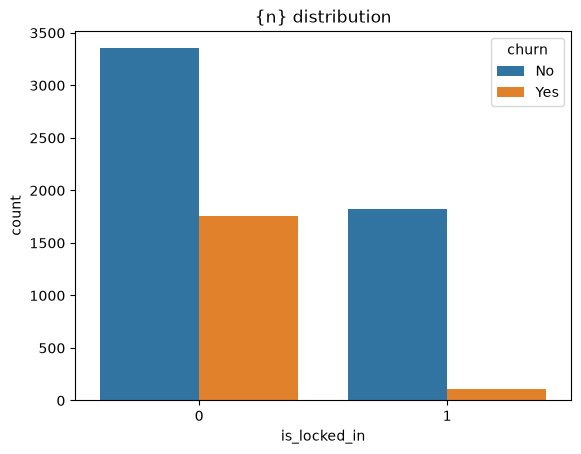

In [35]:
cats = ['gender', 'senior_citizen', 'partner', 'dependents',
       'phone_service', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing',
       'payment_method','tenure_group', 'is_locked_in']
for n in cats:
    sns.countplot(data=df,x=n, hue="churn")
    plt.title("{n} distribution")
    plt.show()

Correlation analysis:

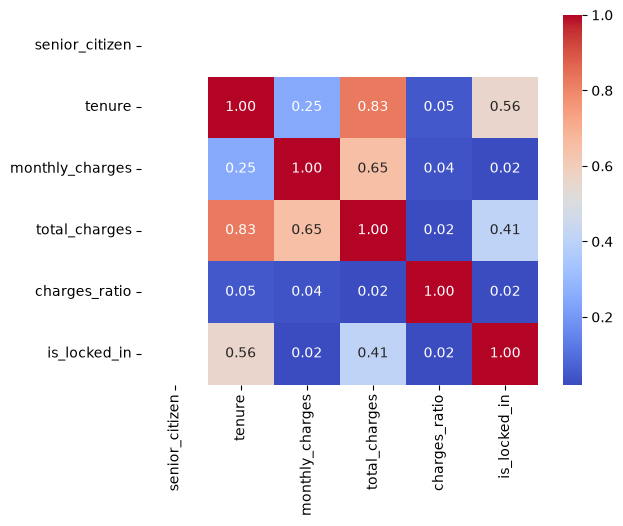

<Figure size 640x480 with 0 Axes>

In [37]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.figure("Correlation analysis")
plt.show()

**Step 7: Define Features (X) and Target (y)**

In [39]:
X = df.drop(columns=['churn'])
y = df['churn']

num_cols = df.select_dtypes(include=[int,float]).columns.to_list()
cat_cols = df.select_dtypes(include=['str','category']).drop(columns=['churn']).columns.to_list()

**Step 8: Train-Test Split**

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

X_train: (5634, 22) | X_test: (1409, 22)


**Step 9: Preprocessing Pipeline**

In [41]:
num_trans = Pipeline([
    ('imp',SimpleImputer(strategy='mean')),
    ('scr',StandardScaler())
])

cat_trans = Pipeline([
    ('imp',SimpleImputer(strategy='most_frequent')),
    ('ohe',OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num_pre',num_trans,num_cols),
    ('cat_trans',cat_trans,cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [42]:
X_train_df = pd.DataFrame(X_train_processed, columns=preprocessor.get_feature_names_out())
X_test_df = pd.DataFrame(X_test_processed, columns=preprocessor.get_feature_names_out())

In [50]:
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

**Step 10: Feature Selection**

In [45]:
selector = VarianceThreshold(threshold=0.01)
X_train_sele = selector.fit_transform(X_train_df)
X_test_sele = selector.transform(X_test_df)
print("X_train shape before feature selection: ",X_train_df.shape)
print("X_train shape after feature selection: ",X_train_sele.shape)
print("\nX_test shape before feature selection: ",X_test_df.shape)
print("X_test shape after feature selection: ",X_test_sele.shape)

X_train shape before feature selection:  (5634, 51)
X_train shape after feature selection:  (5634, 50)

X_test shape before feature selection:  (1409, 51)
X_test shape after feature selection:  (1409, 50)


**Step 11 & 12: Train Models & Regression Metrics**

In [70]:
models = {
    "Logistic Regression":LogisticRegression(C=0.3,max_iter=200, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_split=5, min_samples_leaf=2,random_state=42),
    "Random Forest":RandomForestClassifier(n_estimators=300,max_depth=15, min_samples_split=2, min_samples_leaf=1, n_jobs=-1, random_state=42),
    "XgBoost":XGBClassifier(n_estimators=350, max_depth=6, learning_rate=0.1, random_state=42),
    "SVM": SVC(C=0.01, kernel='rbf', gamma='scale', random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=8, n_jobs=-1),
    "Naive Bayes": GaussianNB()
}

for name, model in models.items():
    model.fit(X_train_sele, y_train_encoded)
    y_pred = model.predict(X_test_sele)
    
    acc = accuracy_score(y_test_encoded, y_pred)
    f1 = f1_score(y_test_encoded, y_pred,zero_division=0)
    pre = precision_score(y_test_encoded, y_pred,zero_division=0)
    re = recall_score(y_test_encoded, y_pred,zero_division=0)
    
    print(f"[{name}] -> Accuracy: {acc*100:.2f}%  -> F1: {f1*100:.4f} | Precision: {pre*100:.4f}  -> Recall: {re*100:.4f}")

[Logistic Regression] -> Accuracy: 81.12%  -> F1: 60.7670 | Precision: 67.5410  -> Recall: 55.2279
[Decision Tree] -> Accuracy: 80.70%  -> F1: 59.7633 | Precision: 66.6667  -> Recall: 54.1555
[Random Forest] -> Accuracy: 80.27%  -> F1: 57.4924 | Precision: 66.9039  -> Recall: 50.4021
[XgBoost] -> Accuracy: 79.42%  -> F1: 57.6023 | Precision: 63.3441  -> Recall: 52.8150
[SVM] -> Accuracy: 73.60%  -> F1: 0.5348 | Precision: 100.0000  -> Recall: 0.2681
[KNN] -> Accuracy: 78.99%  -> F1: 55.0152 | Precision: 63.5088  -> Recall: 48.5255
[Naive Bayes] -> Accuracy: 70.05%  -> F1: 60.4128 | Precision: 46.4646  -> Recall: 86.3271


**Step 13: Cross Validation**

In [71]:
lr_validator = LogisticRegression(C=0.3,max_iter=200, random_state=42)
cv_scores = cross_val_score(lr_validator, X_train_processed, y_train, cv=3, scoring='accuracy')

print(f"3-Fold Cross Validation Individual accuracy Matrix: {cv_scores}")
print(f"Mean Generalization R2 Accuracy: {cv_scores.mean()*100:.2f}%")

3-Fold Cross Validation Individual accuracy Matrix: [0.80617678 0.80351438 0.79605964]
Mean Generalization R2 Accuracy: 80.19%


**Step 14: Hyperparameter Tuning**

In [107]:
param_distributions = {
    'C': [0.1, 0.2, 0.3, 1.0],
    'max_iter': [1000, 2000, 3000]
}

random_search = RandomizedSearchCV(
    estimator=lr_validator,
    param_distributions=param_distributions,
    n_iter=5, 
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_sele, y_train_encoded)
best_tuned_lr = random_search.best_estimator_

print("Optimal Hyperparameter Configurations Found:", random_search.best_params_)


Optimal Hyperparameter Configurations Found: {'max_iter': 3000, 'C': 0.2}


In [111]:
predictions = best_tuned_lr.predict(X_test_sele)
acc = accuracy_score(y_test_encoded, predictions)

print(f"[Tuned Logistic] -> Accuracy: {acc*100:.2f}%")

[Tuned Logistic] -> Accuracy: 81.05%


**Step 15: Feature Importance**

In [110]:
# Changed .feature_importances_ to .coef_[0] because Logistic Regression uses coefficients
important = pd.DataFrame({
    "Feature": X_train_df.columns[selector.get_support()],
    "Importance": best_tuned_lr.coef_[0]
}).sort_values(by="Importance", ascending=False) 

print("\n--- TOP FEATURE IMPORTANCE SCORES ---")
print(important.head(10))



--- TOP FEATURE IMPORTANCE SCORES ---
                                       Feature  Importance
37          cat_trans__contract_Month-to-month    0.707783
46            cat_trans__tenure_group_0-6m_New    0.627385
17     cat_trans__internet_service_Fiber optic    0.436335
44  cat_trans__payment_method_Electronic check    0.250459
19               cat_trans__online_security_No    0.246689
28                  cat_trans__tech_support_No    0.216669
36             cat_trans__streaming_movies_Yes    0.197740
41            cat_trans__paperless_billing_Yes    0.177265
33                 cat_trans__streaming_tv_Yes    0.145104
11                 cat_trans__phone_service_No    0.138963


**Step 16: Final Pipeline Production**

In [88]:
print("Comprehensive automated classification pipeline constructed successfully!")

model_artifact = {
    "model_pipeline": Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('selector',selector),
        ('classifier', best_tuned_lr)
    ]),
    "feature_names": X.columns.tolist(),
    "label_encoder": le
}

model_artifact["model_pipeline"].fit(X_train, y_train)

Comprehensive automated classification pipeline constructed successfully!


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selector', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['gender','senior_citizen','partner',...,'charges_ratio','tenure_group', 'is_locked_in']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pre', ...), ('cat_trans', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By s

**Step 17: Save Model & Load Model**

In [89]:
# Serialize artifact deployment bundle onto disk directly inside the current working directory
joblib.dump(model_artifact, "churn_logistic.pkl")
print("Production artifact saved successfully as 'churn_logistic.pkl'")

Production artifact saved successfully as 'churn_logistic.pkl'


In [90]:
# Test loading structural configuration package integrity
loaded_bundle = joblib.load("churn_logistic.pkl")
production_ready_pipeline = loaded_bundle["model_pipeline"]
print("Model validation verified successfully! Code ready for production web app routing layers.")

Model validation verified successfully! Code ready for production web app routing layers.
